# **Netflix Content Analysis**

## 1. Introduction

This project explores Netflix's content library to identify trends in content types, production countries, genres, audience ratings, and content growth over time. The analysis aims to provide insights into Netflix's catalog using Python for data cleaning, analysis, and visualization.

## 2. Dataset Overview

**Source:** Kaggle

**Dataset:** Netflix Movies and TV Shows

**Records:** 8,790

**Columns:** 12

**Key Variables:**
- **type** – Content type (Movie or TV Show)
- **country** – Country of production
- **listed_in** – Genre(s)
- **rating** – Audience rating
- **release_year** – Original release year
- **date_added** – Date the title was added to Netflix

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.lines as lines

## 3. Data Cleaning

This analysis uses a preprocessed version of the Netflix dataset. The data cleaning process was completed in a separate notebook before the analysis.

The preprocessing included:
- Removing leading and trailing whitespace
- Handling missing values
- Standardizing values in the `rating` column
- Converting `date_added` to datetime format

In [4]:
df = pd.read_csv('../data/Netflix_cleaned.csv')

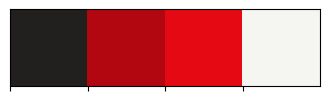

In [5]:
# Netflix Brand Color Palette
sns.palplot(['#221f1f', '#b20710', '#e50914','#f5f5f1'])

## 4. Exploratory Data Analysis (EDA)

### 4.1.  Total Titles in Netflix's Content Library
**Business Question: How many total titles of Netflix's content library?**

In [6]:
total_title = df['title'].count()

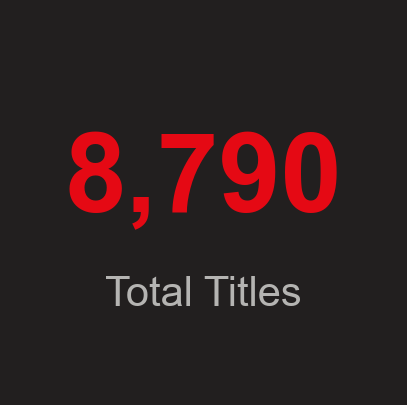

In [7]:
fig, ax = plt.subplots(figsize= (5, 5), facecolor= '#221f1f' )
ax.axis('off')

ax.text(
    0.5, 0.55,
    f'{total_title:,.0f}',
    fontsize= 80,
    font= 'arial',
    fontweight= 'bold',
    ha= 'center',
    va= 'center',
    color= '#e50914'
)

ax.text(
    0.5, 0.23,
    'Total Titles',
    fontsize= 30,
    font= 'arial',
    fontweight= 'medium',
    ha= 'center',
    color= '#f5f5f1',
    alpha= 0.7
)

plt.show()

### 4.2 Movies and TV Shows Distribution
**Business Question: What is the distribution of Movies and TV Shows on Netflix's content library?**

In [8]:
tvshow_movie = df['type'].value_counts()

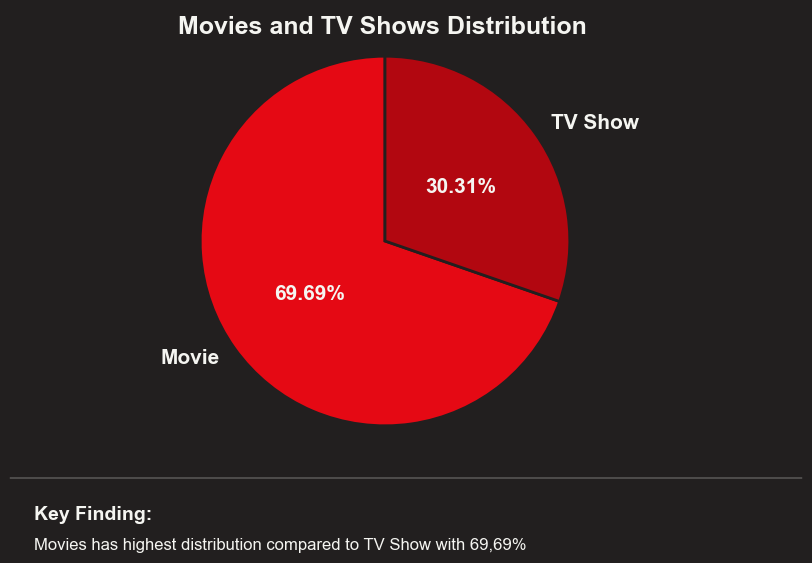

In [9]:
fig, ax = plt.subplots(figsize= (12, 6), facecolor= '#221f1f')

colors = ['#e50914', '#b20710']
text_labels = {'font' : 'arial', 'fontsize' : 15, 'fontweight' : 'bold', 'color' : '#f5f5f1'}
wedge_label = {'edgecolor' : '#221f1f', 'linewidth' : 2, 'width' : 1}
ax.pie(
    tvshow_movie,
    labels= tvshow_movie.index,
    autopct='%1.2f%%',
    pctdistance= 0.5,
    startangle= 90,
    colors= colors,
    wedgeprops= wedge_label,
    textprops= text_labels
)

fig.text(
    0.34, 0.84,
    'Movies and TV Shows Distribution',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 18,
    color= '#f5f5f1'
)

line = lines.Line2D(
    [0.2, 0.86], [0.1, 0.1],
    transform= fig. transFigure, figure= fig, color= '#f5f5f1', lw= 0.3
)
fig.lines.extend([line])

fig.text(
    0.22, 0.03,
    'Key Finding:',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 14,
    color= '#f5f5f1'
)
fig.text(
    0.22, -0.02,
    '''
Movies has highest distribution compared to TV Show with 69,69%''',
    font= 'arial',
    fontweight= 'light',
    fontsize= 12,
    color= '#f5f5f1'
)

plt.show()

### 4.3. Top 10 Countries by Content on Netflix
**Business Question: Which countries produce the most content on Netflix?**

In [10]:
countries = (df['country']
             .str.split(', ')
             .explode()
             .str.strip()
             .value_counts()
             .head(10)
)

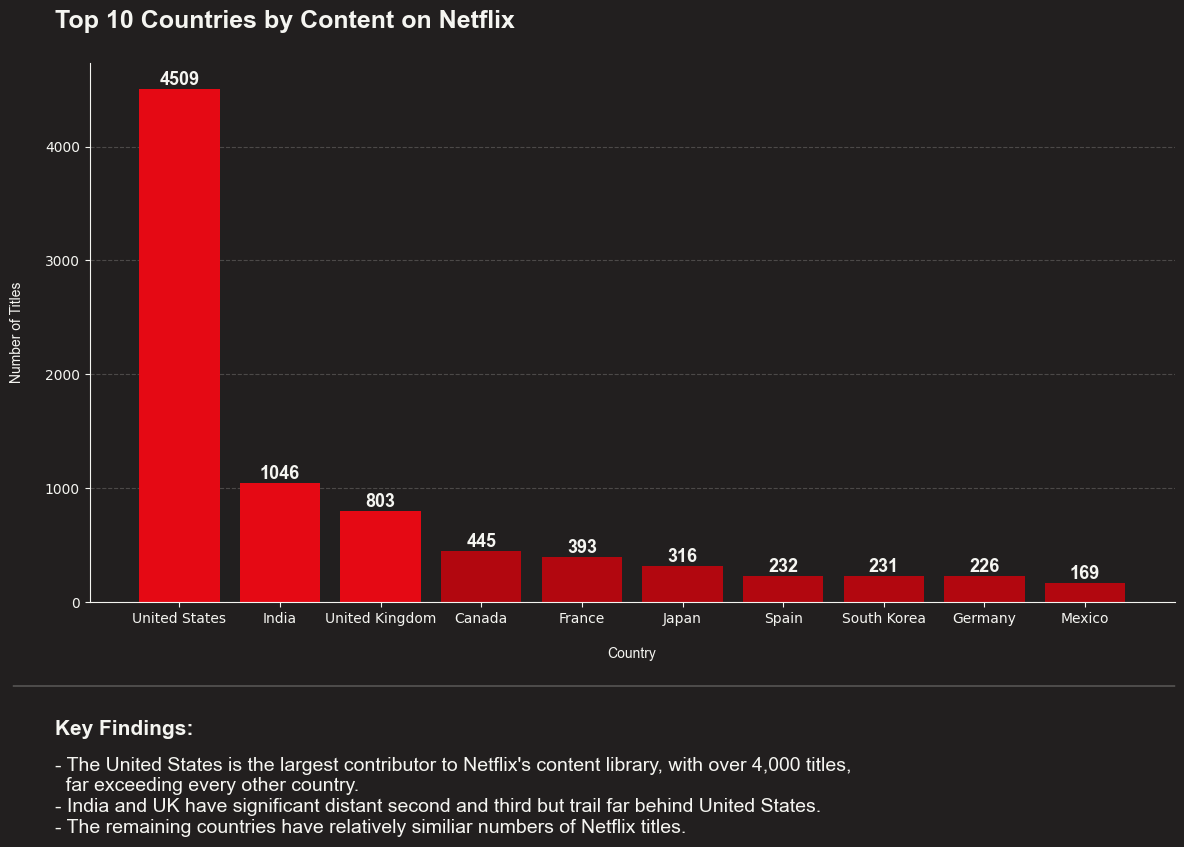

In [11]:
fig, ax = plt.subplots(figsize= (14, 7), facecolor= '#221f1f')
ax.patch.set_color('#221f1f')

for spine in ax.spines.values():
    spine.set_color('#f5f5f1')
ax.tick_params(axis= 'x', colors= '#f5f5f1')
ax.tick_params(axis= 'y', colors= '#f5f5f1')

for i in ['top', 'right']:
    ax.spines[i].set_visible(False)

colors = ["#b2070fff" for _ in range (10)]
colors[0] = colors[1] = colors[2] = '#e50914'

bars = ax.bar(
    countries.index,
    countries.values,
    color= colors
)

ax.bar_label(bars, font= 'arial', fontsize= 13, fontweight= 'semibold', color= '#f5f5f1')
ax.set_xlabel('Country', font= 'arial', fontsize= 10, color= '#f5f5f1', labelpad= 15)
ax.set_ylabel('Number of Titles', font= 'arial', fontsize= 10, color= '#f5f5f1', labelpad= 15)

ax.grid(axis= 'y', linestyle= '--', alpha= 0.2, color= '#f5f5f1')
ax.set_axisbelow(True)

fig.text(
    0.1, 0.93,
    'Top 10 Countries by Content on Netflix',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 18,
    color= '#f5f5f1'
)

line = lines.Line2D(
    [0.07, 0.9], [-0.01, -0.01],
    transform= fig. transFigure, figure= fig, color= '#f5f5f1', lw= 0.3
)
fig.lines.extend([line])

fig.text(
    0.1, -0.08,
    'Key Findings:',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 15,
    color= '#f5f5f1'
)
fig.text(
    0.1, -0.22,
    '''
- The United States is the largest contributor to Netflix's content library, with over 4,000 titles, 
  far exceeding every other country.
- India and UK have significant distant second and third but trail far behind United States.
- The remaining countries have relatively similiar numbers of Netflix titles.''',
    font= 'arial',
    fontweight= 'light',
    fontsize= 14,
    color= '#f5f5f1'
)

plt.show()

### 4.4. Movies & TV Show Distribution by Top 10 Countries
**Business Question: Among the top 10 content-producing countries,  which has the highest proportion of TV Shows compared to Movies?**

In [12]:
country_df = (
    df.assign(country= df['country'].str.split(', '))
    .explode('country').reset_index(drop=True)
)

country_df['country'] = country_df['country'].str.strip()

country_m_tv = pd.crosstab(
    country_df['country'],
    country_df['type']
)

country_m_tv['Total'] = country_m_tv.sum(axis=1)

In [13]:
country_m_tv = country_m_tv.nlargest(10, 'Total')

country_m_tv['Movie Ratio'] = (country_m_tv['Movie'] / country_m_tv['Total'])
country_m_tv['TV Show Ratio'] = (country_m_tv['TV Show'] / country_m_tv['Total'])
country_m_tv = country_m_tv.sort_values(by= ['TV Show Ratio'])

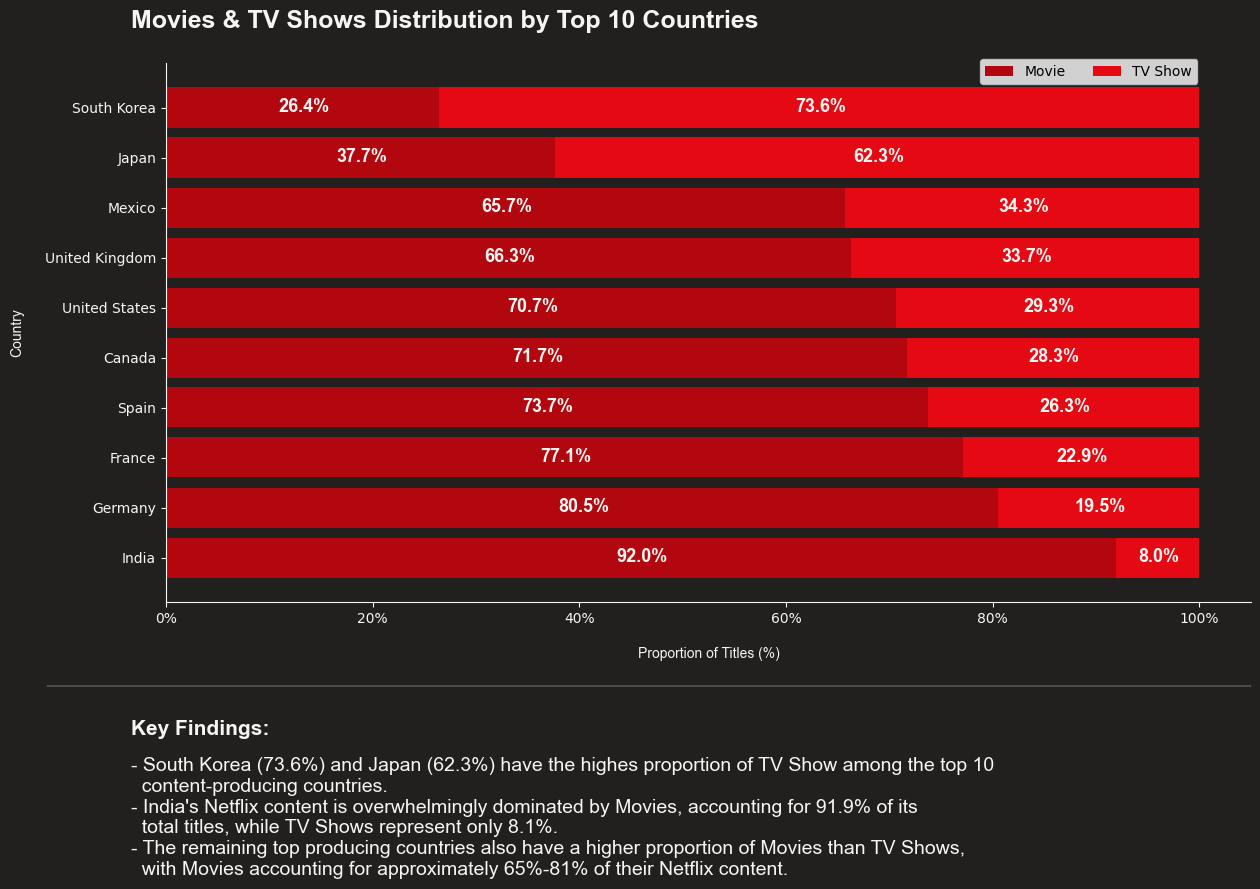

In [14]:
fig, ax = plt.subplots(figsize= (14, 7), facecolor= '#221f1f')
ax.patch.set_color('#221f1f')

for spine in ax.spines.values():
    spine.set_color('#f5f5f1')
ax.tick_params(axis= 'x', colors= '#f5f5f1')
ax.tick_params(axis= 'y', colors= '#f5f5f1')

for i in ['top', 'right']:
    ax.spines[i].set_visible(False)

movie = ax.barh(
    country_m_tv.index,
    country_m_tv['Movie Ratio'],
    color= '#b2070fff',
    label= 'Movie'
)

tv_show = ax.barh(
    country_m_tv.index,
    country_m_tv['TV Show Ratio'],
    left= country_m_tv['Movie Ratio'],
    color= '#e50914',
    label= 'TV Show'
)

ax.bar_label(movie, fmt= '%.0f%%',
             labels= [f'{x:.1%}' for x in country_m_tv['Movie Ratio']],
             label_type= 'center',
             padding= 1,
             font= 'arial', fontsize= 13, fontweight= 'bold', color= '#f5f5f1'
)   
ax.bar_label(tv_show, fmt= '%.0f%%',
             labels= [f'{x:.1%}' for x in country_m_tv['TV Show Ratio']],
             label_type= 'center',
             padding= 1,
             font= 'arial', fontsize= 13, fontweight= 'bold', color= '#f5f5f1'
)

ax.set_xlabel('Proportion of Titles (%)', font= 'arial', fontsize= 10, color= '#f5f5f1', labelpad= 15)
ax.set_ylabel('Country', font= 'arial', fontsize= 10, color= '#f5f5f1', labelpad= 15)


fig.text(
    0.1, 0.93,
    'Movies & TV Shows Distribution by Top 10 Countries',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 18,
    color= '#f5f5f1'
)

line = lines.Line2D(
    [0.04, 0.9], [-0.01, -0.01],
    transform= fig. transFigure, figure= fig, color= '#f5f5f1', lw= 0.3
)
fig.lines.extend([line])

fig.text(
    0.1, -0.08,
    'Key Findings:',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 15,
    color= '#f5f5f1'
)
fig.text(
    0.1, -0.28,
    '''
- South Korea (73.6%) and Japan (62.3%) have the highes proportion of TV Show among the top 10
  content-producing countries.
- India's Netflix content is overwhelmingly dominated by Movies, accounting for 91.9% of its
  total titles, while TV Shows represent only 8.1%.
- The remaining top producing countries also have a higher proportion of Movies than TV Shows,
  with Movies accounting for approximately 65%-81% of their Netflix content.''',
    font= 'arial',
    fontweight= 'light',
    fontsize= 14,
    color= '#f5f5f1'
)
ax.legend(
    loc= 'upper right',
    bbox_to_anchor=(0.957, 1.02),
    ncol= 2
)

from matplotlib.ticker import PercentFormatter
ax.xaxis.set_major_formatter(PercentFormatter(1))

plt.show()

### 4.5. Top 10 Genres by Content on Netflix'
**Business Question: What are the most common genres on Netflix?**

In [15]:
genres = (df['listed_in']
          .str.split(', ')
          .explode()
          .str.strip()
          .value_counts()
          .head(10)
          .sort_values()
)

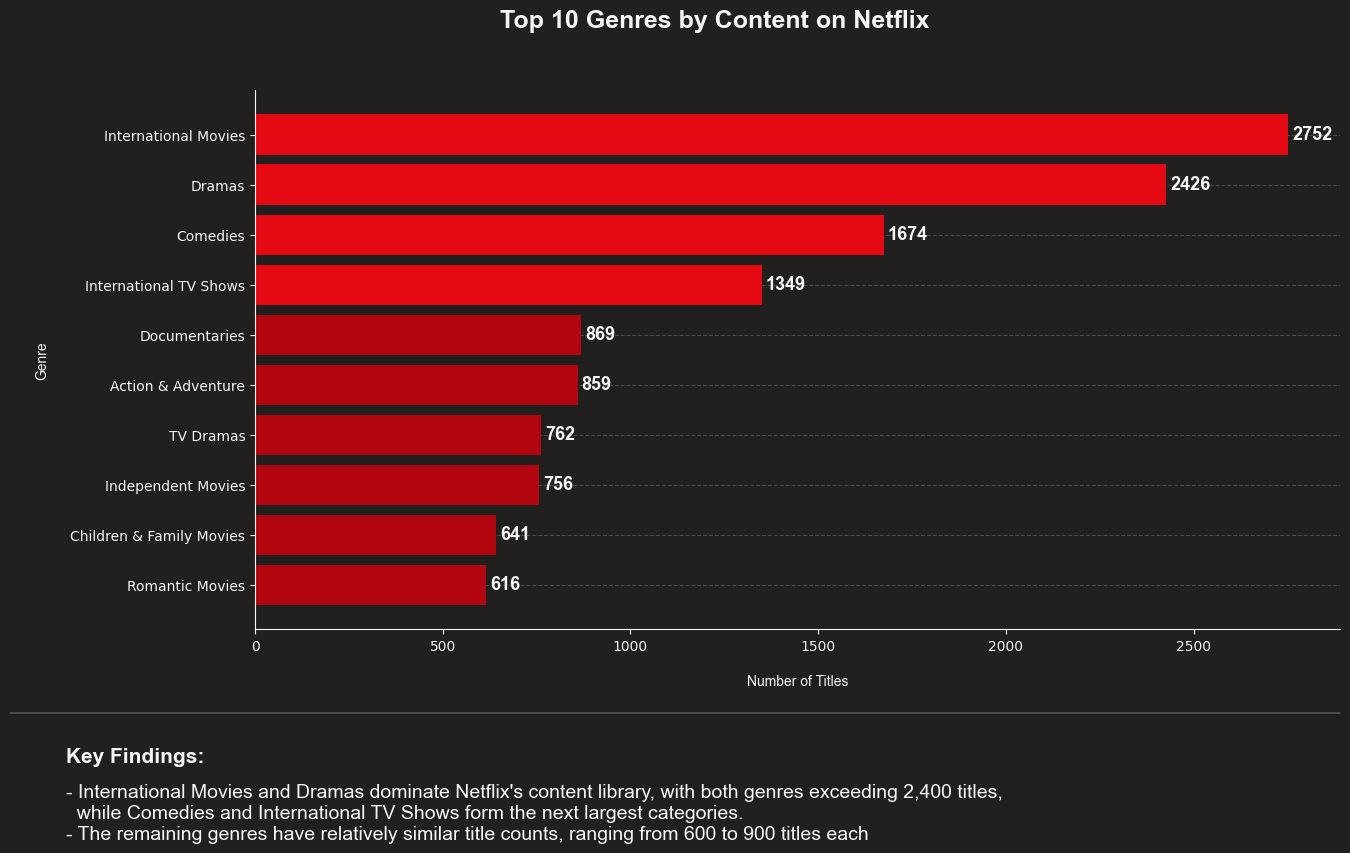

In [16]:
fig, ax = plt.subplots(figsize= (14, 7), facecolor= '#221f1f')
ax.patch.set_color('#221f1f')

for spine in ax.spines.values():
    spine.set_color('#f5f5f1')
ax.tick_params(axis='x', colors= '#f5f5f1')
ax.tick_params(axis='y', colors= '#f5f5f1')

for i in ['top', 'right']:
    ax.spines[i].set_visible(False)

colors = ['#b20710' for _ in range(10)]
colors[9] = colors[8] = colors[7] = colors[6] = '#e50914'

bars = ax.barh(
    genres.index,
    genres.values,
    color= colors
)
ax.bar_label(bars, padding= 3, font= 'arial', fontsize= 13, fontweight= 'semibold', color= '#f5f5f1')
ax.set_xlabel('Number of Titles', font= 'arial', fontsize= 10, color= '#f5f5f1', labelpad= 15)
ax.set_ylabel('Genre', font= 'arial', fontsize= 10, color= '#f5f5f1', labelpad= 15)

ax.grid(axis='y', linestyle= '--', alpha= 0.2, color= '#f5f5f1')
ax.set_axisbelow(True)

fig.text(
    0.3, 0.97,
    'Top 10 Genres by Content on Netflix',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 18,
    color= '#f5f5f1'
)

line = lines.Line2D(
    [-0.05, 0.9], [-0.01, -0.01],
    transform= fig. transFigure, figure= fig, color= '#f5f5f1', lw= 0.3
)
fig.lines.extend([line])

fig.text(
    -0.01, -0.08,
    'Key Findings:',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 15,
    color= '#f5f5f1'
)
fig.text(
    -0.01, -0.19,
    '''
- International Movies and Dramas dominate Netflix's content library, with both genres exceeding 2,400 titles,
  while Comedies and International TV Shows form the next largest categories.
- The remaining genres have relatively similar title counts, ranging from 600 to 900 titles each''',
    font= 'arial',
    fontweight= 'light',
    fontsize= 14,
    color= '#f5f5f1'
)

plt.show()

### 4.6. Top 10 Rating by Content on Netflix
**Business Question: What are the most common audience ratings on Netflix?**

In [17]:
ratings = df['rating'].value_counts().sort_values(ascending=True)

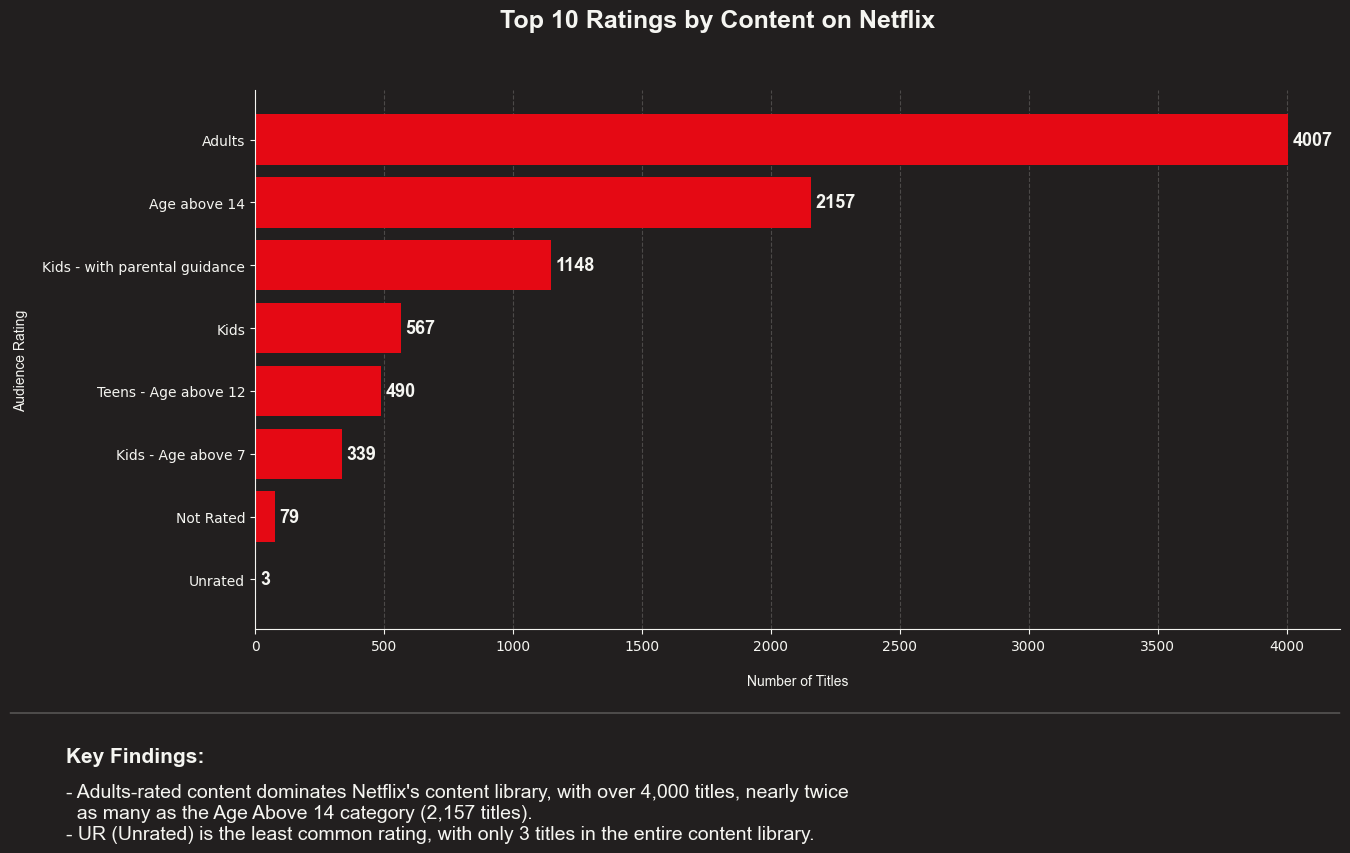

In [18]:
fig, ax = plt.subplots(figsize= (14, 7), facecolor= '#221f1f')
ax.patch.set_color('#221f1f')

for spine in ax.spines.values():
    spine.set_color('#f5f5f1')
ax.tick_params(axis='x', colors= '#f5f5f1')
ax.tick_params(axis='y', colors= '#f5f5f1')

for i in ['top', 'right']:
    ax.spines[i].set_visible(False)

barh = ax.barh(
    ratings.index,
    ratings.values,
    color= '#e50914'
)
ax.bar_label(barh, padding= 3, font= 'arial', fontsize= 13, fontweight= 'semibold', color= '#f5f5f1')
ax.set_xlabel('Number of Titles', font= 'arial', fontsize= 10, color= '#f5f5f1', labelpad= 15)
ax.set_ylabel('Audience Rating', font= 'arial', fontsize= 10, color= '#f5f5f1', labelpad= 10)

ax.grid(axis='x', linestyle= '--', alpha= 0.2, color= '#f5f5f1')
ax.set_axisbelow(True)

fig.text(
    0.3, 0.97,
    'Top 10 Ratings by Content on Netflix',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 18,
    color= '#f5f5f1'
)

line = lines.Line2D(
    [-0.05, 0.9], [-0.01, -0.01],
    transform= fig. transFigure, figure= fig, color= '#f5f5f1', lw= 0.3
)
fig.lines.extend([line])

fig.text(
    -0.01, -0.08,
    'Key Findings:',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 15,
    color= '#f5f5f1'
)
fig.text(
    -0.01, -0.19,
    '''
- Adults-rated content dominates Netflix's content library, with over 4,000 titles, nearly twice
  as many as the Age Above 14 category (2,157 titles).
- UR (Unrated) is the least common rating, with only 3 titles in the entire content library.''',
    font= 'arial',
    fontweight= 'light',
    fontsize= 14,
    color= '#f5f5f1'
)

plt.show()

### 4.7. Netflix's Content Library Growth Over Time
**Business Question: How has Netflix's content library grown over time?**

In [19]:
df['date_added'] = pd.to_datetime(df['date_added'])

content_trend = (df['date_added'].dt.year).value_counts().sort_index()

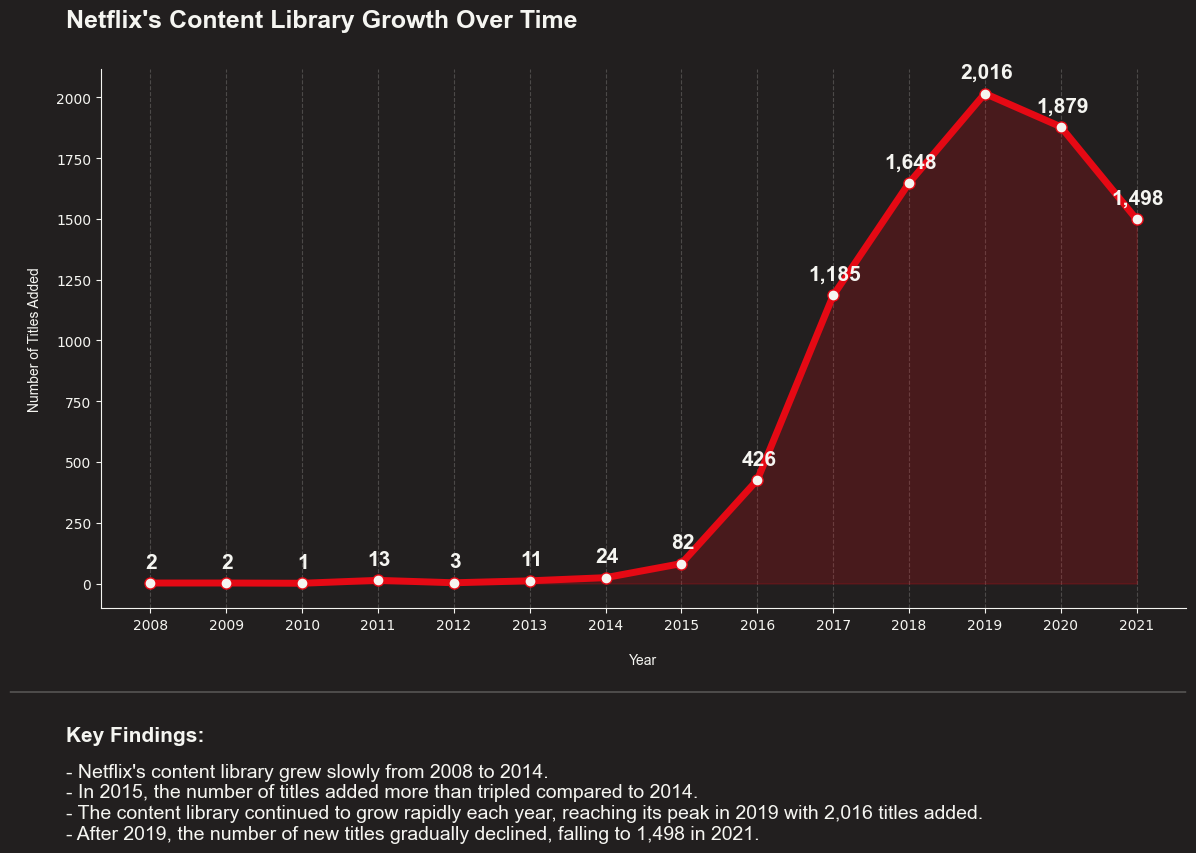

In [20]:
fig, ax = plt.subplots(figsize= (14, 7), facecolor= '#221f1f')
ax.patch.set_color('#221f1f')

for spine in ax.spines.values():
    spine.set_color('#f5f5f1')
ax.tick_params(axis='x', colors= '#f5f5f1')
ax.tick_params(axis='y', colors= '#f5f5f1')
ax.set_xticks(content_trend.index)

for i in ['top', 'right']:
    ax.spines[i].set_visible(False)

ax.grid(axis='x', color= '#f5f5f1', linestyle= '--', alpha= 0.2)
ax.set_axisbelow(True)

ax.plot(
    content_trend.index,
    content_trend.values,
    color= '#e50914',
    marker= 'o',
    markersize= 8,
    markerfacecolor= '#f5f5f1',
    linestyle= '-',
    linewidth= 5,
)

ax.fill_between(
    content_trend.index,
    content_trend.values,
    color= '#e50914',
    alpha= 0.2
)

ax.set_xlabel('Year', font= 'arial', fontsize= 10, color= '#f5f5f1', labelpad= 15)
ax.set_ylabel('Number of Titles Added', font= 'arial', fontsize= 10, color= '#f5f5f1', labelpad= 10)

for x, y in zip(content_trend.index, content_trend.values):
    ax.annotate(
        f'{y:,}',
        (x, y),
        xytext= (1, 15),
        textcoords= 'offset points',
        color= '#f5f5f1',
        font= 'arial', fontsize= 15, fontweight= 'semibold',
        va= 'center', ha= 'center'
    )

fig.text(
    0.1, 0.94,
    "Netflix's Content Library Growth Over Time",
    font= 'arial',
    fontweight= 'bold',
    fontsize= 18,
    color= '#f5f5f1'
)

line = lines.Line2D(
    [0.06, 0.9], [-0.01, -0.01],
    transform= fig. transFigure, figure= fig, color= '#f5f5f1', lw= 0.3
)
fig.lines.extend([line])

fig.text(
    0.1, -0.08,
    'Key Findings:',
    font= 'arial',
    fontweight= 'bold',
    fontsize= 15,
    color= '#f5f5f1'
)
fig.text(
    0.1, -0.22,
    '''
- Netflix's content library grew slowly from 2008 to 2014.
- In 2015, the number of titles added more than tripled compared to 2014.
- The content library continued to grow rapidly each year, reaching its peak in 2019 with 2,016 titles added.
- After 2019, the number of new titles gradually declined, falling to 1,498 in 2021.''',
    font= 'arial',
    fontweight= 'light',
    fontsize= 14,
    color= '#f5f5f1'
)

plt.show()

## 5. Executive Summary

- Netflix's content library dominated by Movies, accounting for 69.89% of all titles, while TV Shows make up the remaining 30.31%.
- United States is leading content-producing country in Netflix's content library with over 4,000 titles, followed by India and United Kingdom with total titles around 1,000 - 800.
- While movies dominate in most countries, several countries have as relatively higher proportion of TV Shows, reflecting regional differences in content production.
- International Movies and Dramas are the most common content category with both genres exceeding 2,400 titles, followed by Comedies and International TV Shows with both exceeding 1,000 titles, indicating Netflix offers a diverse but movie focused catalog.
- Most titles are rated for mature audiences, suggesting Netflix primarily targets adult viewers.
- Netflix's content library expanded rapidly between 2015 and 2019, before experiencing a gradual decline in the number of new titles added through 2020-2021.

## 6. Overall Inisght

Netflix has built a predominantly movie-focused content library by sourcing heavily from major entertainment markets, particularly the United States. The platform experienced its fastest period of content expansion between 2015 and 2019, while maintaining a catalog largely targeted toward mature audiences across a diverse range of genres.

## 7. Conclusion

This analysis provides an overview of Netflix's content library, highlighting trends in content type, production countries, genres, ratings, and growth over time. These findings help illustrate how Netflix expanded its catalog and where its content is primarily sourced.